# U-Net+V3：5折交叉验证与3随机种子实验

本 Notebook 只读取 `Data/Train`，不读取测试集。每个参数配置运行5折 × 3随机种子，共15次外层评估。

外层留出折只在训练结束后评估；最佳epoch由外层训练数据中再划出的10%内部验证集决定。

In [ ]:
from pathlib import Path

# ==================== 路径设置 ====================
DATA_ROOT = Path("/data/wujieyu/1.PyTorch/data/")
TRAIN_IMAGE_DIR = DATA_ROOT / "Train" / "images"
TRAIN_MASK_DIR = DATA_ROOT / "Train" / "masks"

OUTPUT_DIR = Path.cwd() / "outputs_fmm_repeated_cv"
RUNS_DIR = OUTPUT_DIR / "runs"
FIGURE_DIR = OUTPUT_DIR / "figures"
SPLIT_DIR = OUTPUT_DIR / "splits"
PREDICTION_DIR = OUTPUT_DIR / "saved_predictions"

# ==================== 实验参数 ====================
IMAGE_HEIGHT = 288
IMAGE_WIDTH = 384
PERCENTILES = [95, 97, 98, 98.5, 99, 99.5, 99.7, 99.9]
FMM_RADII = [1, 3, 5, 10, 15, 20]

BACKBONE = "inceptionv3"
ENCODER_WEIGHTS = "imagenet"
LEARNING_RATE = 0.001
BATCH_SIZE = 16
EPOCHS = 150

# 三个种子分别生成三套不同的五折划分，同时也用于对应模型的随机初始化。
# 因此本实验是3次重复五折交叉验证，共保存15套划分，而不是同一套五折训练3次。
# 原图基线和全部32组FMM参数严格复用这15套划分，保证配对比较公平。
CV_SEEDS = [42, 123, 2026]
N_SPLITS = 5
INNER_VALIDATION_FRACTION = 0.10

USE_MIXED_PRECISION = True
USE_XLA = False  # TensorFlow 2.6不支持本模型上采样层的XLA梯度
ENABLE_DETERMINISM = False  # TF2.6没有ResizeNearestNeighborGrad的确定性GPU实现
ALLOW_CPU = False
KEEP_FOLD_WEIGHTS = True  # 保留每个配置、种子和折的最佳权重，便于后期重新推理
RUN_EXPERIMENTS = False

# 多GPU/多进程时：设置相同SHARD_COUNT，每个进程使用不同SHARD_ID
SHARD_COUNT = 1
SHARD_ID = 0

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# 必须在导入 TensorFlow 前设置环境变量
import os
os.environ.setdefault("SM_FRAMEWORK", "tf.keras")
os.environ.setdefault("TF_GPU_ALLOCATOR", "cuda_malloc_async")
if ENABLE_DETERMINISM:
    os.environ["TF_DETERMINISTIC_OPS"] = "1"
else:
    os.environ.pop("TF_DETERMINISTIC_OPS", None)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import gc
import json
import random
import sys
import time
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import segmentation_models as sm
from IPython.display import display
from tensorflow.keras import mixed_precision

sm.set_framework("tf.keras")


def set_seed(seed):
    """固定 Python、NumPy 和 TensorFlow 的随机种子。"""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    if hasattr(tf.keras.utils, "set_random_seed"):
        tf.keras.utils.set_random_seed(seed)
    else:
        tf.random.set_seed(seed)


# A800设置：按需分配显存，并启用混合精度
gpus = tf.config.list_physical_devices("GPU")
if not gpus and not ALLOW_CPU:
    raise RuntimeError("没有检测到GPU。如只做代码测试，可把 ALLOW_CPU 改为 True。")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("显存按需分配设置失败：", error)

if ENABLE_DETERMINISM:
    try:
        tf.config.experimental.enable_op_determinism()
    except (AttributeError, RuntimeError):
        print("当前TensorFlow版本不支持确定性算子设置。")

if USE_MIXED_PRECISION and gpus:
    mixed_precision.set_global_policy("mixed_float16")
else:
    mixed_precision.set_global_policy("float32")

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("GPU:", gpus)
print("混合精度:", mixed_precision.global_policy())

Segmentation Models: using `tf.keras` framework.
INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA A800 80GB PCIe, compute capability 8.0
Python: 3.8.18
TensorFlow: 2.9.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
混合精度: <Policy "mixed_float16">


## 1. 读取Data/Train中的全部数据

In [3]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}


def get_stem(path):
    """得到用于图像和掩膜配对的文件名主干。"""
    stem = Path(path).stem.lower()
    for suffix in ("_mask", "-mask"):
        if stem.endswith(suffix):
            stem = stem[:-len(suffix)]
    return stem


def load_data(image_dir, mask_dir):
    """读取一个数据集，返回图像、二值掩膜和文件名。"""
    image_dir = Path(image_dir)
    mask_dir = Path(mask_dir)
    if not image_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError("图像或掩膜目录不存在：%s, %s" % (image_dir, mask_dir))

    image_files = sorted(
        [p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS],
        key=lambda p: p.name.lower(),
    )
    mask_files = {
        get_stem(p): p
        for p in mask_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    }

    images, masks, names = [], [], []
    for image_path in image_files:
        stem = get_stem(image_path)
        if stem not in mask_files:
            raise ValueError("找不到对应掩膜：%s" % image_path.name)

        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(mask_files[stem]), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise ValueError("文件读取失败：%s" % image_path.name)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)

        images.append(image)
        masks.append((mask > 127).astype(np.uint8)[..., None])
        names.append(stem)

    if len(images) != len(mask_files):
        raise ValueError("图像和掩膜数量不一致，请检查是否存在多余掩膜。")

    return (
        np.asarray(images, dtype=np.uint8),
        np.asarray(masks, dtype=np.uint8),
        names,
        image_files,
    )


# 读取训练目录中的全部数据
images, masks, image_names, image_paths = load_data(
    TRAIN_IMAGE_DIR, TRAIN_MASK_DIR
)

print("图像形状：", images.shape, "范围：", images.min(), "~", images.max())
print("掩膜形状：", masks.shape, "取值：", np.unique(masks))
print("样本数量：", len(image_names))

图像形状： (2987, 288, 384, 3) 范围： 0 ~ 255
掩膜形状： (2987, 288, 384, 1) 取值： [0 1]
样本数量： 2987


## 2. 百分位高光掩膜与FMM修复

In [4]:
def original_percentile_mask(original_gray, percentile):
    """与Raw-vs-FMM一致：在原始分辨率灰度图上采用严格大于阈值语义。"""
    threshold = float(np.percentile(original_gray, percentile))
    _, highlight_mask = cv2.threshold(
        original_gray, threshold, 255, cv2.THRESH_BINARY
    )
    return highlight_mask.astype(np.uint8), threshold


def jpeg95_memory_roundtrip(image_bgr):
    """与Raw-vs-FMM一致：JPG质量95编码后重新读取BGR图像。"""
    success, encoded = cv2.imencode(
        ".jpg", image_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 95]
    )
    if not success:
        raise OSError("OpenCV JPG质量95内存编码失败。")
    decoded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    if decoded is None:
        raise OSError("OpenCV JPG内存解码失败。")
    return decoded


def restore_original_fmm(original_bgr, original_gray, percentile, radius):
    """原始Mask→0.6倍三次插值→TELEA→384×288→JPG95→RGB。"""
    if original_gray.shape != original_bgr.shape[:2]:
        raise ValueError("彩色原图与灰度原图尺寸不一致。")

    highlight_mask, threshold = original_percentile_mask(
        original_gray, percentile
    )
    scaled_image = cv2.resize(
        original_bgr, None, fx=0.6, fy=0.6,
        interpolation=cv2.INTER_CUBIC
    )
    scaled_mask = cv2.resize(
        highlight_mask, None, fx=0.6, fy=0.6,
        interpolation=cv2.INTER_CUBIC
    )
    restored = cv2.inpaint(
        scaled_image, scaled_mask, float(radius), cv2.INPAINT_TELEA
    )
    restored = cv2.resize(
        restored, (IMAGE_WIDTH, IMAGE_HEIGHT),
        interpolation=cv2.INTER_LINEAR
    )
    restored = jpeg95_memory_roundtrip(restored)
    return cv2.cvtColor(restored, cv2.COLOR_BGR2RGB), highlight_mask, threshold


def fmm_restore_dataset(input_paths, percentile, radius):
    """从原始分辨率文件执行与Raw-vs-FMM一致的完整高光修复流程。"""
    input_paths = [Path(path) for path in input_paths]
    restored_images = np.empty(
        (len(input_paths), IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.uint8
    )
    mask_ratios = np.empty(len(input_paths), dtype=np.float64)

    for i, image_path in enumerate(input_paths):
        original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        original_gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if original_bgr is None or original_gray is None:
            raise OSError("图像读取失败：%s" % image_path)

        restored, highlight_mask, _ = restore_original_fmm(
            original_bgr, original_gray, percentile, radius
        )
        restored_images[i] = restored
        mask_ratios[i] = np.count_nonzero(highlight_mask) / highlight_mask.size

        if (i + 1) % 100 == 0 or i + 1 == len(input_paths):
            print("修复进度：%d/%d" % (i + 1, len(input_paths)), end="\r")

    print()
    return restored_images, float(mask_ratios.mean())


def config_name(percentile, radius):
    percentile_text = str(percentile).replace(".", "p")
    return "fmm_p%s_r%d" % (percentile_text, radius)


# 小型检查：严格阈值、缩放、FMM、JPG95、RGB和最终尺寸。
test_bgr = np.zeros((IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.uint8)
test_bgr[:, :, 0] = np.linspace(0, 200, IMAGE_WIDTH, dtype=np.uint8)
test_bgr[20:40, 20:40] = 255
test_gray = cv2.cvtColor(test_bgr, cv2.COLOR_BGR2GRAY)

test_mask, test_threshold = original_percentile_mask(test_gray, 99.0)
assert np.count_nonzero(test_mask) > 0
assert set(np.unique(test_mask)).issubset({0, 255})
assert np.all(test_mask[test_gray <= test_threshold] == 0)

test_r1, _, _ = restore_original_fmm(test_bgr, test_gray, 99.0, 1)
test_r10, _, _ = restore_original_fmm(test_bgr, test_gray, 99.0, 10)
assert test_r1.shape == (IMAGE_HEIGHT, IMAGE_WIDTH, 3)
assert test_r1.dtype == np.uint8
assert not np.array_equal(test_r1, test_r10)
print("Raw-vs-FMM完整高光修复流程检查通过")


Raw-vs-FMM完整高光修复流程检查通过


## 3. 定义损失、指标和U-Net+InceptionV3模型

In [5]:
def bce_jaccard_loss(y_true, y_pred, smooth=1e-7, alpha=0.5):
    """BCE与Jaccard Loss各占一半。"""
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true + y_pred) - intersection
    jaccard_loss = 1.0 - (intersection + smooth) / (union + smooth)
    return alpha * bce + (1.0 - alpha) * jaccard_loss


def dice_score(y_true, y_pred, smooth=1e-7):
    """使用0.5阈值计算硬Dice。"""
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred, axis=(1, 2, 3))
    total = tf.reduce_sum(y_true + y_pred, axis=(1, 2, 3))
    return tf.reduce_mean((2.0 * intersection + smooth) / (total + smooth))


def iou_score(y_true, y_pred, smooth=1e-7):
    """使用0.5阈值计算硬IoU。"""
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred, axis=(1, 2, 3))
    union = tf.reduce_sum(y_true + y_pred, axis=(1, 2, 3)) - intersection
    return tf.reduce_mean((intersection + smooth) / (union + smooth))


def build_model(seed, use_xla=True):
    """建立与原U-net+V3 Notebook一致的模型。"""
    tf.keras.backend.clear_session()
    set_seed(seed)

    base_model = sm.Unet(
        BACKBONE,
        input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3),
        classes=1,
        activation=None,
        encoder_weights=ENCODER_WEIGHTS,
    )

    # 混合精度下用float32输出分割概率，避免指标计算不稳定
    output = tf.keras.layers.Activation("sigmoid", dtype="float32")(base_model.output)
    model = tf.keras.Model(base_model.input, output)

    compile_args = {
        "optimizer": tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        "loss": bce_jaccard_loss,
        "metrics": [dice_score, iou_score],
    }
    if use_xla:
        compile_args["jit_compile"] = True
    model.compile(**compile_args)
    return model

### 逐图指标与tf.data数据管线

In [6]:
def calculate_per_image_metrics(prediction, true_mask):
    """计算每张图像的Dice和IoU。"""
    pred = prediction >= 0.5
    true = true_mask >= 0.5
    axes = (1, 2, 3)

    intersection = np.logical_and(pred, true).sum(axis=axes)
    pred_area = pred.sum(axis=axes)
    true_area = true.sum(axis=axes)
    union = pred_area + true_area - intersection

    dice = np.divide(
        2.0 * intersection,
        pred_area + true_area,
        out=np.ones(len(prediction), dtype=float),
        where=(pred_area + true_area) > 0,
    )
    iou = np.divide(
        intersection,
        union,
        out=np.ones(len(prediction), dtype=float),
        where=union > 0,
    )
    return dice, iou


def make_dataset(x, y, training, seed):
    """建立批处理数据管线，并提前准备下一批数据。"""
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        dataset = dataset.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### 单次训练、验证和结果保存

In [7]:
def train_one_run(
    run_name,
    run_images,
    train_index,
    model_val_index,
    evaluation_index,
    seed,
    epochs,
    extra_info,
    keep_weights=True,
):
    """训练一次模型，并保存训练历史、最佳权重和逐图指标。"""
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    summary_file = run_dir / "summary.json"
    weights_file = run_dir / "best.weights.h5"
    backup_dir = run_dir / "training_backup"

    # 保留权重时，summary和最佳权重必须同时存在才算完整结束
    if summary_file.exists() and (not keep_weights or weights_file.exists()):
        print("已完成，跳过：", run_name)
        return json.loads(summary_file.read_text(encoding="utf-8"))

    train_x = run_images[train_index].astype(np.float32) / 255.0
    train_y = masks[train_index].astype(np.float32)
    val_x = run_images[model_val_index].astype(np.float32) / 255.0
    val_y = masks[model_val_index].astype(np.float32)
    eval_x = run_images[evaluation_index].astype(np.float32) / 255.0
    eval_y = masks[evaluation_index].astype(np.float32)

    train_data = make_dataset(train_x, train_y, training=True, seed=seed)
    val_data = make_dataset(val_x, val_y, training=False, seed=seed)
    eval_data = make_dataset(eval_x, eval_y, training=False, seed=seed)

    history_file = run_dir / "history.csv"
    attempts = [True, False] if USE_XLA else [False]
    start_time = time.time()

    for use_xla in attempts:
        try:
            model = build_model(seed, use_xla=use_xla)
            callbacks = [
                # 每轮保存训练状态；中断后从上一轮末尾继续训练
                tf.keras.callbacks.BackupAndRestore(str(backup_dir)),
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor="val_iou_score",
                    factor=0.5,
                    patience=20,
                    mode="max",
                    verbose=1,
                ),
                tf.keras.callbacks.ModelCheckpoint(
                    str(weights_file),
                    monitor="val_iou_score",
                    save_best_only=True,
                    save_weights_only=True,
                    mode="max",
                    verbose=1,
                ),
                tf.keras.callbacks.CSVLogger(
                    str(history_file), append=backup_dir.exists()
                ),
                tf.keras.callbacks.TerminateOnNaN(),
            ]

            history = model.fit(
                train_data,
                epochs=epochs,
                validation_data=val_data,
                callbacks=callbacks,
                verbose=2,
            )
            break
        except (TypeError, tf.errors.InvalidArgumentError, tf.errors.UnimplementedError) as error:
            if not use_xla:
                raise
            print("当前环境不支持XLA，关闭XLA后重新训练：", error)
            tf.keras.backend.clear_session()
            gc.collect()

    model.load_weights(str(weights_file))
    prediction = model.predict(eval_data, verbose=0)
    dice, iou = calculate_per_image_metrics(prediction, eval_y)

    metric_table = pd.DataFrame({
        "sample_index": evaluation_index,
        "image_name": [image_names[i] for i in evaluation_index],
        "dice": dice,
        "iou": iou,
    })
    for key, value in extra_info.items():
        metric_table[key] = value
    metric_table.to_csv(run_dir / "per_image_metrics.csv", index=False)

    # 从完整CSV历史中寻找最佳epoch，兼容中断恢复后的追加记录
    full_history = pd.read_csv(history_file)
    best_epoch = int(full_history.loc[full_history["val_iou_score"].idxmax(), "epoch"]) + 1
    summary = dict(extra_info)
    summary.update({
        "run_name": run_name,
        "seed": int(seed),
        "best_epoch": best_epoch,
        "mean_dice": float(dice.mean()),
        "std_dice": float(dice.std(ddof=1)),
        "mean_iou": float(iou.mean()),
        "std_iou": float(iou.std(ddof=1)),
        "sample_count": int(len(evaluation_index)),
        "training_seconds": float(time.time() - start_time),
        "xla_used": bool(use_xla),
        "weights_file": str(weights_file) if keep_weights else None,
    })
    summary_file.write_text(
        json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"
    )

    if not keep_weights and weights_file.exists():
        weights_file.unlink()

    del model, prediction, train_data, val_data, eval_data
    del train_x, train_y, val_x, val_y, eval_x, eval_y
    tf.keras.backend.clear_session()
    gc.collect()
    return summary

## 4. 生成5折和内部验证集

In [8]:
from sklearn.model_selection import KFold, train_test_split


def repeated_folds(sample_count):
    """生成3次重复五折，共15套不同的训练/验证/外层测试划分。"""
    # 每个seed都会重新打乱样本并生成一套新的5折。
    # 对于任意一个seed，每张图像恰好有一次作为outer_test。
    # 因此每个参数配置对每张图像最终会得到3次外层测试预测。
    all_index = np.arange(sample_count)

    for seed in CV_SEEDS:
        kfold = KFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
        for fold, (outer_train, outer_test) in enumerate(kfold.split(all_index), start=1):
            inner_train, inner_val = train_test_split(
                outer_train,
                test_size=INNER_VALIDATION_FRACTION,
                random_state=seed + fold,
                shuffle=True,
            )

            # 三部分必须互不重叠
            assert np.intersect1d(inner_train, inner_val).size == 0
            assert np.intersect1d(inner_train, outer_test).size == 0
            assert np.intersect1d(inner_val, outer_test).size == 0

            yield seed, fold, inner_train, inner_val, outer_test


def expected_split_files():
    """返回本实验应当存在的15个划分文件。"""
    return [
        SPLIT_DIR / ("seed_%d_fold_%d.npz" % (seed, fold))
        for seed in CV_SEEDS
        for fold in range(1, N_SPLITS + 1)
    ]


def validate_saved_splits(manifest_file):
    """确认已保存划分仍与当前图像文件名和样本数量一致。"""
    saved_manifest = pd.read_csv(manifest_file, dtype={"image_name": str})
    saved_names = (
        saved_manifest[["sample_index", "image_name"]]
        .drop_duplicates()
        .sort_values("sample_index")["image_name"]
        .tolist()
    )
    if saved_names != image_names:
        raise ValueError(
            "已保存的交叉验证划分与当前Data/Train文件不一致，"
            "为避免覆盖旧划分，程序已停止。"
        )

    for split_file in expected_split_files():
        split_data = np.load(split_file)
        all_index = np.concatenate([
            split_data["inner_train"],
            split_data["inner_val"],
            split_data["outer_test"],
        ])
        if len(all_index) != len(images) or len(np.unique(all_index)) != len(images):
            raise ValueError("划分文件不完整或包含重复索引：%s" % split_file)


def save_cv_splits():
    """只在首次运行时生成划分；完整划分存在时直接复用。"""
    split_files = expected_split_files()
    manifest_file = SPLIT_DIR / "cv_split_manifest.csv"
    existing_files = [path for path in split_files if path.exists()]

    if manifest_file.exists() and len(existing_files) == len(split_files):
        validate_saved_splits(manifest_file)
        print("检测到完整的15套交叉验证划分，校验通过，跳过重新生成。")
        return

    if manifest_file.exists() or existing_files:
        raise RuntimeError(
            "splits目录中只存在部分划分文件。程序不会自动覆盖，"
            "请先检查并备份该目录。"
        )

    split_rows = []
    for seed, fold, inner_train, inner_val, outer_test in repeated_folds(len(images)):
        np.savez(
            SPLIT_DIR / ("seed_%d_fold_%d.npz" % (seed, fold)),
            inner_train=inner_train, inner_val=inner_val, outer_test=outer_test,
        )
        for role, index_array in [
            ("inner_train", inner_train),
            ("inner_val", inner_val),
            ("outer_test", outer_test),
        ]:
            for sample_index in index_array:
                split_rows.append({
                    "seed": seed, "fold": fold, "role": role,
                    "sample_index": int(sample_index),
                    "image_name": image_names[sample_index],
                })
        print("seed=%d, fold=%d: train=%d, val=%d, test=%d" % (
            seed, fold, len(inner_train), len(inner_val), len(outer_test)
        ))

    pd.DataFrame(split_rows).to_csv(manifest_file, index=False)
    validate_saved_splits(manifest_file)
    print("首次生成的15套交叉验证划分已保存到：", SPLIT_DIR)


def load_saved_folds():
    """训练时只读取首次保存的划分，不再调用KFold重新划分。"""
    for seed in CV_SEEDS:
        for fold in range(1, N_SPLITS + 1):
            split_file = SPLIT_DIR / ("seed_%d_fold_%d.npz" % (seed, fold))
            split_data = np.load(split_file)
            yield (
                seed, fold,
                split_data["inner_train"],
                split_data["inner_val"],
                split_data["outer_test"],
            )


save_cv_splits()

检测到完整的15套交叉验证划分，校验通过，跳过重新生成。


## 5. 运行原图基线和参数的重复交叉验证

In [9]:
def finished_run_count(config_id):
    """统计同时保存了结果和最佳权重的训练次数。"""
    completed = 0
    for summary_file in RUNS_DIR.glob(config_id + "__seed_*__fold_*/summary.json"):
        weights_file = summary_file.parent / "best.weights.h5"
        if not KEEP_FOLD_WEIGHTS or weights_file.exists():
            completed += 1
    return completed


def run_one_config(job, current_images, mask_area):
    """同一配置连续运行3个种子、每个种子5折。"""
    for seed, fold, inner_train, inner_val, outer_test in load_saved_folds():
        run_name = "%s__seed_%d__fold_%d" % (job["config_id"], seed, fold)
        print("\n当前训练：", run_name)

        train_one_run(
            run_name=run_name,
            run_images=current_images,
            train_index=inner_train,
            model_val_index=inner_val,
            evaluation_index=outer_test,
            seed=seed,
            epochs=EPOCHS,
            extra_info={
                "config_id": job["config_id"],
                "percentile": job["percentile"],
                "radius": job["radius"],
                "fold": fold,
                "mean_mask_area_ratio": mask_area,
            },
            keep_weights=KEEP_FOLD_WEIGHTS,
        )


if RUN_EXPERIMENTS:
    if not 0 <= SHARD_ID < SHARD_COUNT:
        raise ValueError("SHARD_ID必须满足 0 <= SHARD_ID < SHARD_COUNT")

    # 原图基线只在0号分片运行
    baseline = {"config_id": "baseline_raw", "percentile": None, "radius": None}
    if SHARD_ID == 0 and finished_run_count("baseline_raw") < 15:
        run_one_config(baseline, images, mask_area=0.0)

    jobs = []
    for percentile in PERCENTILES:
        for radius in FMM_RADII:
            jobs.append({
                "config_id": config_name(percentile, radius),
                "percentile": percentile,
                "radius": radius,
            })

    # 按配置编号分片，避免两个进程运行同一参数
    my_jobs = [
        job for i, job in enumerate(jobs)
        if i % SHARD_COUNT == SHARD_ID
    ]
    print("当前分片负责%d组参数" % len(my_jobs))

    for number, job in enumerate(my_jobs, start=1):
        print("\n==============================")
        print("参数 %d/%d：%s" % (number, len(my_jobs), job["config_id"]))

        if finished_run_count(job["config_id"]) == 15:
            print("该参数的15次训练均已完成，跳过。")
            continue

        # 同一参数只修复一次，生成的数组供15次训练重复使用
        current_images, mask_area = fmm_restore_dataset(
            image_paths, job["percentile"], job["radius"]
        )
        run_one_config(job, current_images, mask_area)
        del current_images
        gc.collect()
else:
    print("RUN_EXPERIMENTS=False，当前只检查代码和数据，不开始训练。")

RUN_EXPERIMENTS=False，当前只检查代码和数据，不开始训练。


## 6. 汇总15次外层评估和统计检验

In [10]:
def save_parameter_figures(result_table, figure_dir, prefix):
    """绘制热力图、阈值曲线和相对原图基线变化图。"""
    figure_dir.mkdir(parents=True, exist_ok=True)
    parameter_table = result_table[result_table["config_id"] != "baseline_raw"].copy()
    if parameter_table.empty:
        return

    heatmap = parameter_table.pivot(
        index="percentile", columns="radius", values="mean_iou"
    ).sort_index()

    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(heatmap.values, cmap="viridis", aspect="auto", origin="lower")
    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    ax.set_xlabel("FMM radius")
    ax.set_ylabel("Percentile")
    ax.set_title("IoU heatmap")
    for row in range(len(heatmap.index)):
        for column in range(len(heatmap.columns)):
            ax.text(column, row, "%.4f" % heatmap.iloc[row, column],
                    ha="center", va="center", color="white", fontsize=8)
    fig.colorbar(image, ax=ax)
    fig.savefig(figure_dir / (prefix + "_heatmap.png"), dpi=300, bbox_inches="tight")
    fig.savefig(figure_dir / (prefix + "_heatmap.pdf"), bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 5))
    for radius, group in parameter_table.groupby("radius"):
        group = group.sort_values("percentile")
        ax.plot(group["percentile"], group["mean_iou"], marker="o", label="radius=%d" % radius)
    ax.set_xlabel("Percentile")
    ax.set_ylabel("Mean IoU")
    ax.set_title("Threshold sensitivity")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.savefig(figure_dir / (prefix + "_threshold_curve.png"), dpi=300, bbox_inches="tight")
    fig.savefig(figure_dir / (prefix + "_threshold_curve.pdf"), bbox_inches="tight")
    plt.show()

    baseline = result_table[result_table["config_id"] == "baseline_raw"]
    if len(baseline):
        delta = heatmap - float(baseline.iloc[0]["mean_iou"])
        limit = max(abs(delta.min().min()), abs(delta.max().max()), 1e-6)
        fig, ax = plt.subplots(figsize=(8, 6))
        image = ax.imshow(delta.values, cmap="coolwarm", vmin=-limit, vmax=limit,
                          aspect="auto", origin="lower")
        ax.set_xticks(range(len(delta.columns)))
        ax.set_xticklabels(delta.columns)
        ax.set_yticks(range(len(delta.index)))
        ax.set_yticklabels(delta.index)
        ax.set_xlabel("FMM radius")
        ax.set_ylabel("Percentile")
        ax.set_title("IoU change relative to raw images")
        fig.colorbar(image, ax=ax)
        fig.savefig(figure_dir / (prefix + "_relative_to_baseline.png"), dpi=300, bbox_inches="tight")
        fig.savefig(figure_dir / (prefix + "_relative_to_baseline.pdf"), bbox_inches="tight")
        plt.show()

全部配置交叉验证结果（按平均IoU从高到低）：


,config_id,percentile,radius,completed_runs,mean_iou,std_iou,mean_dice,std_dice,mean_mask_area_ratio,mean_training_seconds
0,fmm_p99p5_r10,99.5,10.0,15,0.769186,0.011969,0.829324,0.011359,0.007287,4847.836594
1,fmm_p98p5_r10,98.5,10.0,15,0.767504,0.006470,0.828355,0.005612,0.016622,3544.241837
2,fmm_p99p7_r1,99.7,1.0,15,0.767267,0.009944,0.828398,0.009331,0.005512,3017.335606
3,fmm_p98p5_r15,98.5,15.0,15,0.766703,0.007170,0.827608,0.006639,0.016622,2933.020786
4,fmm_p99p5_r1,99.5,1.0,15,0.766490,0.014105,0.827224,0.013743,0.007287,3711.393751
5,fmm_p99p5_r3,99.5,3.0,15,0.766400,0.008027,0.827388,0.008127,0.007287,3575.098038
6,baseline_raw,NaN,NaN,15,0.766284,0.006677,0.826823,0.006729,0.000000,3562.313472
7,fmm_p99_r1,99.0,1.0,15,0.766194,0.009969,0.826841,0.009735,0.011892,2990.118160
8,fmm_p99p9_r5,99.9,5.0,15,0.766144,0.009260,0.826113,0.009305,0.003334,3037.031005
9,fmm_p99p7_r3,99.7,3.0,15,0.766137,0.008048,0.826484,0.008828,0.005512,3016.129407


全部配置相对原图基线的配对统计检验：


,config_id,percentile,radius,mean_iou_difference,mean_dice_difference,paired_t_iou_p,paired_t_dice_p,wilcoxon_iou_p,wilcoxon_dice_p,paired_t_iou_p_holm,paired_t_dice_p_holm,wilcoxon_iou_p_holm,wilcoxon_dice_p_holm
0,fmm_p95_r1,95.0,1.0,-0.009627,-0.008963,6.880634e-03,0.009793,0.012451,0.018066,0.282106,0.401497,0.485596,0.722656
1,fmm_p95_r10,95.0,10.0,-0.014261,-0.013205,2.190166e-06,0.000003,0.000061,0.000061,0.000103,0.000130,0.002930,0.002930
2,fmm_p95_r15,95.0,15.0,-0.013456,-0.011557,4.286641e-07,0.000007,0.000061,0.000061,0.000021,0.000319,0.002930,0.002930
3,fmm_p95_r20,95.0,20.0,-0.010266,-0.008861,2.989922e-04,0.000477,0.000183,0.000854,0.013156,0.021485,0.008423,0.039307
4,fmm_p95_r3,95.0,3.0,-0.011918,-0.010468,7.611994e-05,0.000418,0.000427,0.001526,0.003502,0.019206,0.019226,0.068665
5,fmm_p95_r5,95.0,5.0,-0.011753,-0.010084,2.415193e-04,0.000545,0.002625,0.002625,0.010868,0.024000,0.110229,0.115479
6,fmm_p97_r1,97.0,1.0,-0.004088,-0.004408,8.240868e-02,0.064433,0.168823,0.106995,1.000000,1.000000,1.000000,1.000000
7,fmm_p97_r10,97.0,10.0,-0.005112,-0.004923,5.651713e-02,0.084741,0.063721,0.083252,1.000000,1.000000,1.000000,1.000000
8,fmm_p97_r15,97.0,15.0,-0.002797,-0.002582,2.139772e-01,0.226055,0.252380,0.389404,1.000000,1.000000,1.000000,1.000000
9,fmm_p97_r20,97.0,20.0,-0.007171,-0.006801,1.979067e-03,0.002949,0.001526,0.004272,0.085100,0.123843,0.067139,0.179443


交叉验证最佳参数： fmm_p99p5_r10


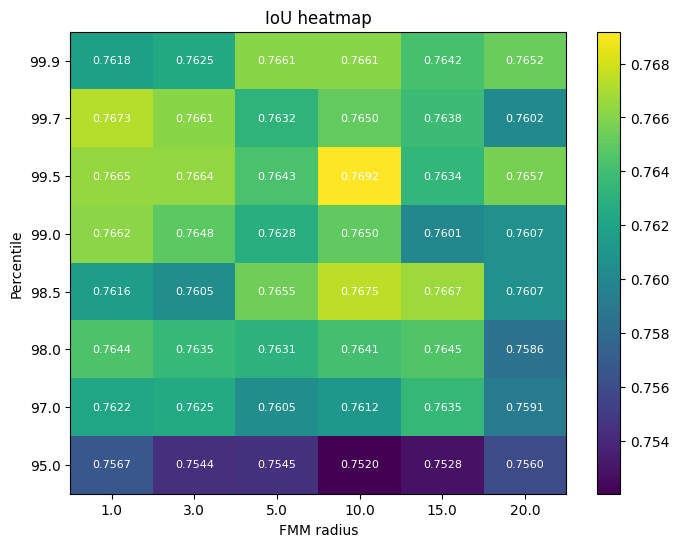

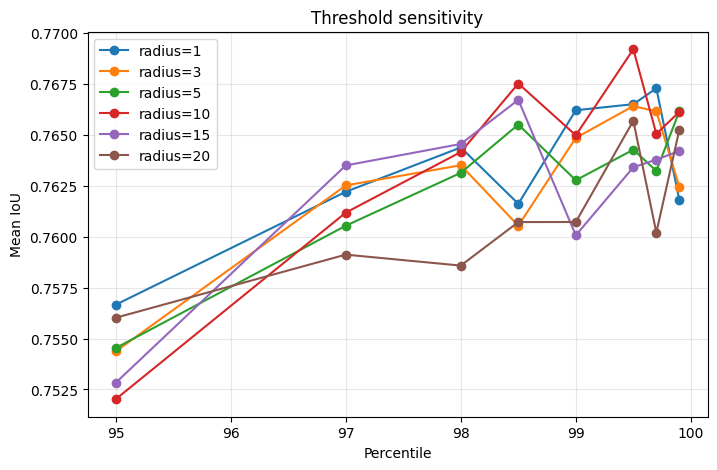

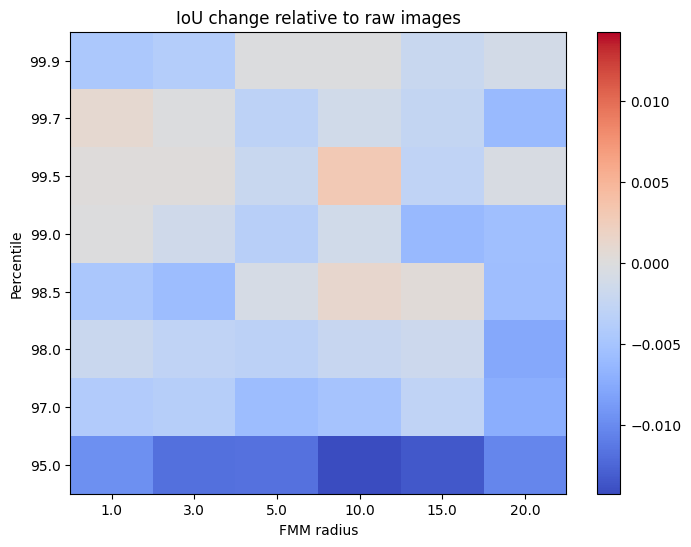

In [11]:
from scipy.stats import ttest_rel, wilcoxon


def holm_correction(p_values):
    """Holm多重比较校正。"""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    previous = 0.0

    for rank, index in enumerate(order):
        value = min(1.0, (len(p_values) - rank) * p_values[index])
        previous = max(previous, value)
        adjusted[index] = previous
    return adjusted


summary_files = sorted(RUNS_DIR.glob("*/summary.json"))

if not summary_files:
    print("目前没有已完成的交叉验证结果。")
else:
    cv_fold_results = pd.DataFrame([
        json.loads(path.read_text(encoding="utf-8"))
        for path in summary_files
    ]).sort_values(["config_id", "seed", "fold"])
    cv_fold_results.to_csv(OUTPUT_DIR / "cv_fold_results.csv", index=False)

    metric_files = sorted(RUNS_DIR.glob("*/per_image_metrics.csv"))
    cv_per_image_metrics = pd.concat(
        [pd.read_csv(path) for path in metric_files], ignore_index=True
    )
    cv_per_image_metrics.to_csv(
        OUTPUT_DIR / "cv_per_image_metrics.csv", index=False
    )

    # 每个配置汇总15次外层评估
    summary_rows = []
    for config_id, group in cv_fold_results.groupby("config_id"):
        summary_rows.append({
            "config_id": config_id,
            "percentile": group["percentile"].iloc[0],
            "radius": group["radius"].iloc[0],
            "completed_runs": len(group),
            "mean_iou": group["mean_iou"].mean(),
            "std_iou": group["mean_iou"].std(ddof=1),
            "mean_dice": group["mean_dice"].mean(),
            "std_dice": group["mean_dice"].std(ddof=1),
            "mean_mask_area_ratio": group["mean_mask_area_ratio"].mean(),
            "mean_training_seconds": group["training_seconds"].mean(),
        })

    cv_parameter_summary = pd.DataFrame(summary_rows).sort_values(
        "mean_iou", ascending=False
    )
    cv_parameter_summary.to_csv(
        OUTPUT_DIR / "cv_parameter_summary.csv", index=False
    )

    print("全部配置交叉验证结果（按平均IoU从高到低）：")
    display(cv_parameter_summary.reset_index(drop=True))

    # 每组修复参数与相同seed、相同fold的原图基线进行配对检验
    baseline = cv_fold_results[
        cv_fold_results["config_id"] == "baseline_raw"
    ][["seed", "fold", "mean_iou", "mean_dice"]]

    statistics_rows = []
    for config_id, group in cv_fold_results.groupby("config_id"):
        if config_id == "baseline_raw" or len(group) != 15 or len(baseline) != 15:
            continue

        paired = group.merge(
            baseline, on=["seed", "fold"], suffixes=("_fmm", "_raw")
        )
        iou_difference = paired["mean_iou_fmm"] - paired["mean_iou_raw"]
        dice_difference = paired["mean_dice_fmm"] - paired["mean_dice_raw"]

        try:
            wilcoxon_iou_p = wilcoxon(iou_difference).pvalue
        except ValueError:
            wilcoxon_iou_p = 1.0
        try:
            wilcoxon_dice_p = wilcoxon(dice_difference).pvalue
        except ValueError:
            wilcoxon_dice_p = 1.0

        statistics_rows.append({
            "config_id": config_id,
            "percentile": group["percentile"].iloc[0],
            "radius": group["radius"].iloc[0],
            "mean_iou_difference": iou_difference.mean(),
            "mean_dice_difference": dice_difference.mean(),
            "paired_t_iou_p": ttest_rel(
                paired["mean_iou_fmm"], paired["mean_iou_raw"]
            ).pvalue,
            "paired_t_dice_p": ttest_rel(
                paired["mean_dice_fmm"], paired["mean_dice_raw"]
            ).pvalue,
            "wilcoxon_iou_p": wilcoxon_iou_p,
            "wilcoxon_dice_p": wilcoxon_dice_p,
        })

    cv_statistics = pd.DataFrame(statistics_rows)
    if len(cv_statistics):
        for column in [
            "paired_t_iou_p", "paired_t_dice_p",
            "wilcoxon_iou_p", "wilcoxon_dice_p",
        ]:
            cv_statistics[column + "_holm"] = holm_correction(
                cv_statistics[column].values
            )
        cv_statistics.to_csv(
            OUTPUT_DIR / "cv_paired_statistics.csv", index=False
        )
        print("全部配置相对原图基线的配对统计检验：")
        display(cv_statistics.reset_index(drop=True))

    completed = cv_parameter_summary[
        (cv_parameter_summary["config_id"] != "baseline_raw") &
        (cv_parameter_summary["completed_runs"] == 15)
    ].copy()
    if len(completed):
        best_iou = completed["mean_iou"].max()
        tied = completed[completed["mean_iou"] >= best_iou - 1e-4]
        tied = tied.sort_values(["percentile", "radius"], ascending=[False, True])
        best_config = tied.iloc[0].to_dict()
        (OUTPUT_DIR / "best_config_cross_validation.json").write_text(
            json.dumps(best_config, indent=2, ensure_ascii=False), encoding="utf-8"
        )
        print("交叉验证最佳参数：", best_config["config_id"])

    complete_for_plot = cv_parameter_summary[
        cv_parameter_summary["completed_runs"] == 15
    ]
    save_parameter_figures(complete_for_plot, FIGURE_DIR, "repeated_cv")

## 7. 后期加载折权重并重新生成分割结果

In [12]:
def infer_saved_outer_fold(config_id, percentile, radius, seed, fold):
    """加载指定折的最佳权重，对该折外层测试图像重新推理。"""
    split_file = SPLIT_DIR / ("seed_%d_fold_%d.npz" % (seed, fold))
    if not split_file.exists():
        raise FileNotFoundError("找不到折划分文件：%s" % split_file)

    split_data = np.load(split_file)
    outer_test = split_data["outer_test"]
    outer_images = images[outer_test]

    if config_id == "baseline_raw":
        inference_images = outer_images
    else:
        if percentile is None or radius is None:
            raise ValueError("FMM配置必须提供percentile和radius。")
        outer_paths = [image_paths[int(i)] for i in outer_test]
        inference_images, _ = fmm_restore_dataset(
            outer_paths, percentile, radius
        )

    run_name = "%s__seed_%d__fold_%d" % (config_id, seed, fold)
    weights_file = RUNS_DIR / run_name / "best.weights.h5"
    if not weights_file.exists():
        raise FileNotFoundError("找不到最佳权重：%s" % weights_file)

    model = build_model(seed, use_xla=False)
    model.load_weights(str(weights_file))
    probability = model.predict(
        inference_images.astype(np.float32) / 255.0,
        batch_size=BATCH_SIZE,
        verbose=1,
    )
    binary_mask = (probability >= 0.5).astype(np.uint8)
    dice, iou = calculate_per_image_metrics(probability, masks[outer_test])

    save_dir = PREDICTION_DIR / run_name
    save_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        save_dir / "outer_fold_predictions.npz",
        sample_index=outer_test,
        image_name=np.asarray([image_names[i] for i in outer_test]),
        probability=probability.astype(np.float16),
        binary_mask=binary_mask,
    )

    result_table = pd.DataFrame({
        "sample_index": outer_test,
        "image_name": [image_names[i] for i in outer_test],
        "dice": dice,
        "iou": iou,
    })
    result_table.to_csv(save_dir / "outer_fold_metrics.csv", index=False)

    del model
    tf.keras.backend.clear_session()
    gc.collect()
    print("分割结果已保存到：", save_dir)
    return probability, result_table


# 后期需要重新生成分割结果时，取消下面相应代码的注释
# probability, metrics = infer_saved_outer_fold(
#     config_id="fmm_p99p5_r3", percentile=99.5, radius=3, seed=42, fold=1
# )
# baseline_probability, baseline_metrics = infer_saved_outer_fold(
#     config_id="baseline_raw", percentile=None, radius=None, seed=42, fold=1
# )

## 8. 筛选并显示失败案例

In [13]:
def select_failure_cases(method_metrics, baseline_metrics=None, top_k=5):
    """筛选低IoU案例，或筛选相对原图基线下降最多的案例。"""
    method_table = method_metrics.reset_index(drop=True).copy()
    method_table["method_position"] = np.arange(len(method_table))

    # 没有基线结果时，以当前方法IoU最低作为失败案例
    if baseline_metrics is None:
        return method_table.sort_values("iou").head(top_k)

    # 有基线结果时，优先找FMM相对原图下降最多的图像
    baseline_table = baseline_metrics.reset_index(drop=True).copy()
    baseline_table["baseline_position"] = np.arange(len(baseline_table))
    comparison = method_table.merge(
        baseline_table[[
            "sample_index", "baseline_position", "dice", "iou"
        ]],
        on="sample_index",
        suffixes=("_fmm", "_raw"),
    )
    comparison["delta_dice"] = comparison["dice_fmm"] - comparison["dice_raw"]
    comparison["delta_iou"] = comparison["iou_fmm"] - comparison["iou_raw"]
    degraded = comparison[comparison["delta_iou"] < 0].sort_values("delta_iou")
    if len(degraded):
        return degraded.head(top_k)

    print("本折没有FMM性能下降案例，下面返回改善最小的案例。")
    return comparison.sort_values("delta_iou").head(top_k)


def visualize_failure_cases(
    method_probability,
    method_metrics,
    baseline_probability=None,
    baseline_metrics=None,
    top_k=5,
):
    """显示原图、真实掩膜、原图模型预测和FMM模型预测。"""
    cases = select_failure_cases(method_metrics, baseline_metrics, top_k)
    has_baseline = baseline_probability is not None and baseline_metrics is not None
    column_count = 4 if has_baseline else 3

    fig, axes = plt.subplots(
        len(cases), column_count, figsize=(4 * column_count, 3.5 * len(cases))
    )
    if len(cases) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_number, (_, case) in enumerate(cases.iterrows()):
        sample_index = int(case["sample_index"])
        method_position = int(case["method_position"])

        axes[row_number, 0].imshow(images[sample_index])
        axes[row_number, 0].set_title(image_names[sample_index])
        axes[row_number, 1].imshow(masks[sample_index, :, :, 0], cmap="gray")
        axes[row_number, 1].set_title("Ground truth")

        if has_baseline:
            baseline_position = int(case["baseline_position"])
            axes[row_number, 2].imshow(
                baseline_probability[baseline_position, :, :, 0] >= 0.5, cmap="gray"
            )
            axes[row_number, 2].set_title("Raw IoU=%.3f" % case["iou_raw"])
            method_column = 3
            method_title = "FMM IoU=%.3f, delta=%.3f" % (
                case["iou_fmm"], case["delta_iou"]
            )
        else:
            method_column = 2
            method_title = "IoU=%.3f" % case["iou"]

        axes[row_number, method_column].imshow(
            method_probability[method_position, :, :, 0] >= 0.5, cmap="gray"
        )
        axes[row_number, method_column].set_title(method_title)

        for axis in axes[row_number]:
            axis.axis("off")

    plt.tight_layout()
    plt.show()
    return cases


# 推荐用法：比较同一seed、同一fold下的原图基线和FMM结果
# fmm_probability, fmm_metrics = infer_saved_outer_fold(
#     "fmm_p99p5_r3", 99.5, 3, seed=42, fold=1
# )
# raw_probability, raw_metrics = infer_saved_outer_fold(
#     "baseline_raw", None, None, seed=42, fold=1
# )
# failure_cases = visualize_failure_cases(
#     fmm_probability, fmm_metrics, raw_probability, raw_metrics, top_k=5
# )